In [1]:
import numpy as np
import seaborn as sns
import pandas as pd

In [2]:
 data = sns.load_dataset('penguins')
 data.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
data.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [4]:
data['sex'] = data['sex'].fillna(data['sex'].mode()[0])
data['bill_length_mm'] = data['bill_length_mm'].fillna(data['bill_length_mm'].mean())
data['bill_depth_mm'] = data['bill_depth_mm'].fillna(data['bill_depth_mm'].mean())
data['flipper_length_mm'] = data['flipper_length_mm'].fillna(data['flipper_length_mm'].mean())
data['body_mass_g'] = data['body_mass_g'].fillna(data['body_mass_g'].mean())

In [5]:
data.isnull().sum()

,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


Gender Composition

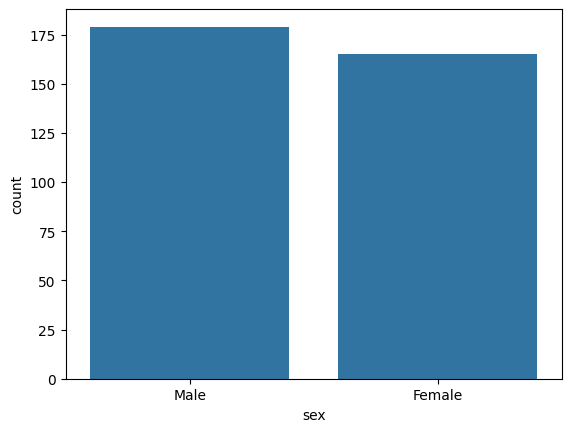

In [6]:
import matplotlib.pyplot as plt
sns.countplot(x='sex', data=data)
plt.show()


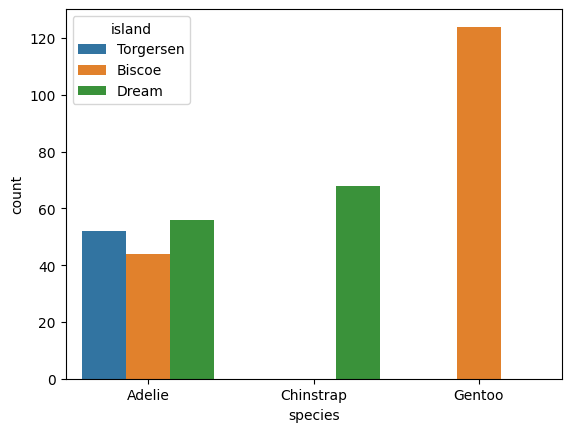

In [7]:
sns.countplot(x= 'species',hue='island',data = data)
plt.show()

Creating a Violin PLot to visualize our bill_length_mm

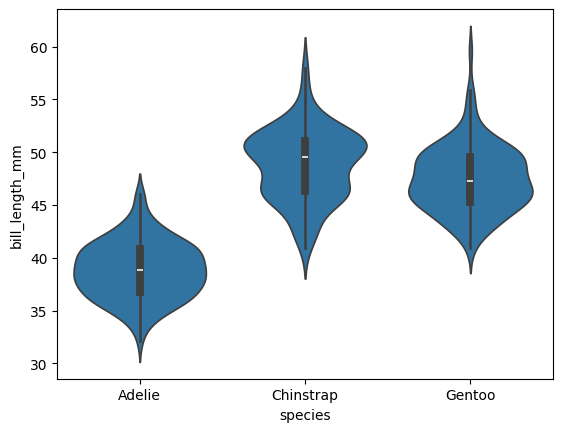

In [8]:
sns.violinplot(x='species',y='bill_length_mm',data=data)
plt.show()

Joint Plot

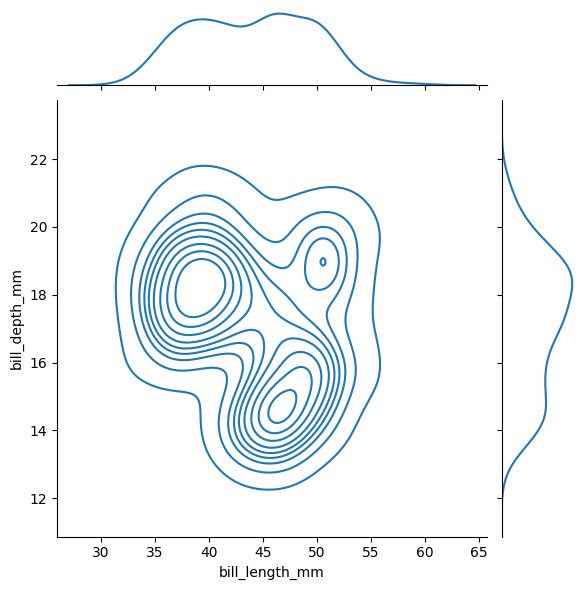

In [9]:
sns.jointplot(x='bill_length_mm',y='bill_depth_mm',data=data,kind='kde')
plt.show()

Heatmap

In [10]:
numeric_features = data.select_dtypes(include =['int64','float64'])
numeric_features

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.10000,18.70000,181.000000,3750.000000
1,39.50000,17.40000,186.000000,3800.000000
2,40.30000,18.00000,195.000000,3250.000000
3,43.92193,17.15117,200.915205,4201.754386
4,36.70000,19.30000,193.000000,3450.000000
...,...,...,...,...
339,43.92193,17.15117,200.915205,4201.754386
340,46.80000,14.30000,215.000000,4850.000000
341,50.40000,15.70000,222.000000,5750.000000
342,45.20000,14.80000,212.000000,5200.000000


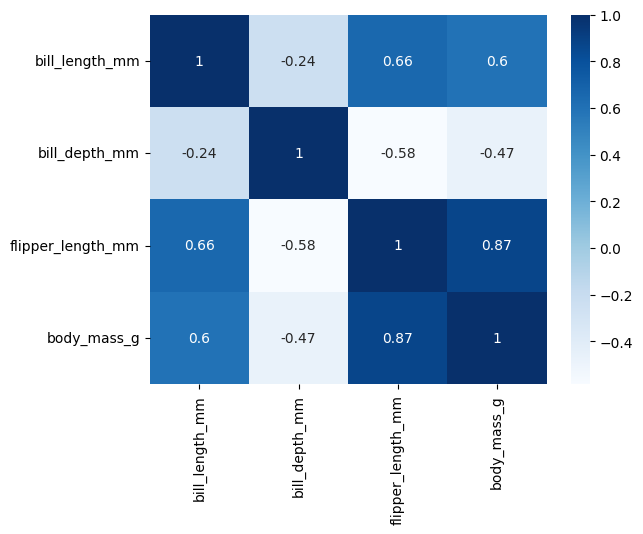

In [ ]:
sns.heatmap(numeric_features.corr(),annot = True,cmap='Blues')
plt.show()

In [11]:
numeric_features.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,344.000000,344.000000,344.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.443643,1.969027,14.020657,799.613058
min,32.100000,13.100000,172.000000,2700.000000
25%,39.275000,15.600000,190.000000,3550.000000
50%,44.250000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


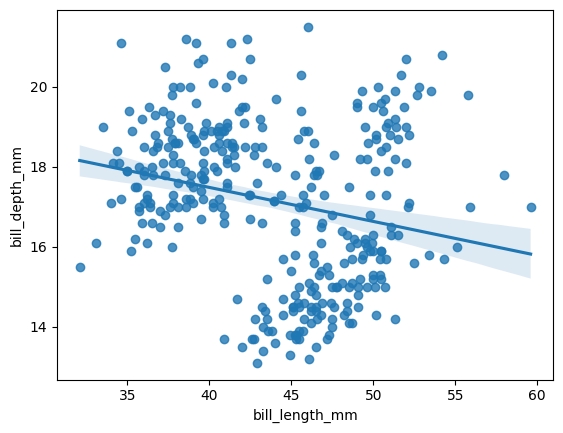

In [12]:
sns.regplot(x='bill_length_mm',y='bill_depth_mm',data=data)
plt.show()

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     344 non-null    float64
 3   bill_depth_mm      344 non-null    float64
 4   flipper_length_mm  344 non-null    float64
 5   body_mass_g        344 non-null    float64
 6   sex                344 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


Converting the Features with text with numeric features

In [13]:
#Encoding
data['sex'] = data['sex'].map({'Male':1,"Female":2})
data['island'] = data['island'].map({'Torgersen':1,"Biscoe":2,'Dream':3})

In [14]:
data['sex'].value_counts()

,count
sex,
1,179
2,165


In [15]:
data['sex']

,sex
0,1
1,2
2,2
3,1
4,2
...,...
339,1
340,2
341,1
342,2


In [16]:
x = data.drop('species',axis=1)
y = data['species']

Splitting the data into test set and trainig set

In [17]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(275, 6)
(69, 6)
(275,)
(69,)


In [18]:
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression()
log_model.fit(x_train,y_train)

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [19]:
y_pred = log_model.predict(x_test)
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

0.9710144927536232
[[31  0  1]
 [ 0 15  1]
 [ 0  0 21]]


In [20]:
data['species'].value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


In [21]:
from sklearn.model_selection import cross_validate
cv = cross_validate(log_model,x,y,cv=5,scoring = ['accuracy','recall','precision'])
print("The cross validation accuracy of our model is :",cv['test_accuracy'].mean())
print("The cross validation recall of our model is :",cv['test_recall'].mean())
print("The cross validation precision of our model is :",cv['test_precision'].mean())

The cross validation accuracy of our model is : 0.9854219948849104
The cross validation recall of our model is : nan
The cross validation precision of our model is : nan


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_scorer.py", line 140, in __call__
    score = scorer._score(
            ^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_scorer.py", line 388, in _score
 

## Random Forest

In [22]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier()
rf_model.fit(x_train,y_train)

RandomForestClassifier()

In [23]:
y_pred = rf_model.predict(x_test)

In [24]:
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

0.9855072463768116
[[31  0  1]
 [ 0 16  0]
 [ 0  0 21]]


## Hyperparamter Tuning

In [28]:
param_space = {
    'n_estimators':(1,100),
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}


In [31]:
from sklearn.model_selection import GridSearchCV
Scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro'
}
grid_search = GridSearchCV(rf_model,param_space,cv=5,scoring = Scoring ,refit = 'accuracy')
grid_search.fit(x_train,y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': (1, 100)},
             refit='accuracy',
             scoring={'accuracy': 'accuracy', 'precision': 'precision_macro',
                      'recall': 'recall_macro'})

In [32]:
rf_model = grid_search.best_estimator_
rf_model.fit(x_train,y_train)

RandomForestClassifier(criterion='entropy', max_depth=30, min_samples_leaf=2)

In [33]:
y_pred = rf_model.predict(x_test)
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

1.0
[[32  0  0]
 [ 0 16  0]
 [ 0  0 21]]


## Cross- Validation of the Model

In [37]:
from sklearn.model_selection import cross_validate
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro'
}
cv = cross_validate(rf_model,x,y,cv= 5 , scoring = scoring)
print("The cross validation accuracy of our model is",cv['test_accuracy'].mean()*100)
print("The cross validation recall of our model is",cv['test_recall'].mean()*100)
print("The cross validation precision of our model is",cv['test_precision'].mean()*100)

The cross validation accuracy of our model is 98.54219948849105
The cross validation recall of our model is 98.58653353814645
The cross validation precision of our model is 98.36431131592424


Saving our model as a pickle file

In [38]:
import pickle
pickle.dump(rf_model,open('penguin_model2.pkl','wb'))